# Part 2 — Positive definite matrices

From TOML-MIRI *Linear Algebra for Data Science* — exploration exercises (sheet section [2.6–2.7, 3.1, 3.5]).

Topic exercises:

- **2.1** The shape of a quadratic form
- **2.2** A sphere becomes an ellipsoid
- **2.3** A⊤ A is always PSD

This notebook implements **2.1**, **2.2** and **2.3**. Each exercise keeps the sheet's three parts — **Task**, **Explore**, **Explain** — and every identity carries a one-line np.allclose check.

## Setup

Shared imports and helpers for the whole notebook. The helper returns the matrix, the plotting grid, its eigenvalues and eigenvectors, and a classification of the quadratic form.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

np.set_printoptions(precision=4, suppress=True)


def quadratic_grid(a, b, c, lim=2.0, n=81):
    """Return S, X, Y, Z for f(x) = x^T S x on the square [-lim, lim]^2."""
    S = np.array([[a, b], [b, c]], dtype=float)
    x = np.linspace(-lim, lim, n)
    y = np.linspace(-lim, lim, n)
    X, Y = np.meshgrid(x, y)
    Z = a * X**2 + 2.0 * b * X * Y + c * Y**2
    return S, X, Y, Z


def shape_type(vals, tol=1e-10):
    """Classify a symmetric 2x2 matrix from its eigenvalues."""
    lo, hi = np.sort(np.asarray(vals, dtype=float))
    if lo > tol and hi > tol:
        return "positive definite: bowl"
    if lo >= -tol and hi > tol:
        return "positive semidefinite: valley with a flat line"
    if lo < -tol and hi < -tol:
        return "negative definite: upside-down bowl"
    if lo < -tol and hi <= tol:
        return "negative semidefinite: ridge with a flat line"
    if lo < -tol and hi > tol:
        return "indefinite: saddle"
    return "zero matrix: flat plane"


def eigen_summary(a, b, c, lim=2.0, n=81):
    """All numbers used by the figures, for one choice of (a, b, c)."""
    S, X, Y, Z = quadratic_grid(a, b, c, lim=lim, n=n)
    vals, vecs = np.linalg.eigh(S)
    Y1 = X * vecs[0, 0] + Y * vecs[1, 0]
    Y2 = X * vecs[0, 1] + Y * vecs[1, 1]
    return dict(S=S, X=X, Y=Y, Z=Z, vals=vals, vecs=vecs, Y1=Y1, Y2=Y2,
                det=np.linalg.det(S), trace=np.trace(S),
                kind=shape_type(vals))


def summary_text(a, b, c):
    d = eigen_summary(a, b, c)
    v = d["vals"]
    return ("a = %+.2f, b = %+.2f, c = %+.2f<br>"
            "eigenvalues: %+.3f, %+.3f<br>"
            "det = %+.3f, trace = %+.3f<br>"
            "%s" % (a, b, c, v[0], v[1], d["det"], d["trace"], d["kind"]))


def eigen_text(d, lim=2.0):
    v, Q = d["vals"], d["vecs"]
    p1 = 0.92 * lim * Q[:, 0]
    p2 = 0.92 * lim * Q[:, 1]
    return ([p1[0], p2[0]], [p1[1], p2[1]],
            ["q1  λ=%+.2f" % v[0], "q2  λ=%+.2f" % v[1]])


def rotation_matrix(theta_deg):
    """Q = [[cos, -sin], [sin, cos]]; its columns are the eigen-directions."""
    t = np.radians(theta_deg)
    return np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])


def ellipse_stages(theta_deg, lam1, lam2, n=241):
    """The four stages that turn the unit circle into the ellipse S = Q diag(lam) Q^T.

        v  ->  Q^T v  ->  Lambda Q^T v  ->  Q Lambda Q^T v = S v.
    """
    Q = rotation_matrix(theta_deg)
    L = np.diag([lam1, lam2]).astype(float)
    S = Q @ L @ Q.T
    t = np.linspace(0.0, 2.0 * np.pi, n)
    V = np.vstack([np.cos(t), np.sin(t)])
    V1 = Q.T @ V
    V2 = L @ V1
    V3 = Q @ V2
    return dict(Q=Q, L=L, S=S, t=t, V=V, V1=V1, V2=V2, V3=V3,
                lam1=float(lam1), lam2=float(lam2))


# cyclic colour scale so the marked points stay identifiable through Q^T
_cm = plt.get_cmap("twilight")
TWILIGHT = [[i / 63.0, "rgb(%d,%d,%d)"
             % tuple(int(round(255 * c)) for c in _cm(i / 63.0)[:3])]
            for i in range(64)]


## 2.1 — The shape of a quadratic form

### Task

Plot the surface and the contour lines of

    f(x) = x^T S x,      S = [ a  b ]
                              [ b  c ]

with sliders for a, b and c. Show the eigenvalues and draw the eigenvectors on the
contour plot.

The default matrix is S = [[1, 0.5], [0.5, 2]]. The three sliders sweep one
coefficient at a time around that default; the buttons above the figure jump to the
four canonical shapes (PD bowl, PSD valley, ND bowl, saddle).

In [2]:
# --- Task: default quadratic form, eigen-data and checks -----------------
a0, b0, c0 = 1.0, 0.5, 2.0
GRID_N = 41
d0 = eigen_summary(a0, b0, c0, n=GRID_N)
S0, vals0, Q0 = d0["S"], d0["vals"], d0["vecs"]

print("S =")
print(S0)
print("\neigenvalues (ascending):", vals0)
print("eigenvectors (columns of Q):")
print(Q0)
print("\ndet(S) = %+.4f   trace(S) = %+.4f" % (d0["det"], d0["trace"]))
print("classification:", d0["kind"])
for i in range(2):
    q = Q0[:, i]
    print("q%d = (%+.4f, %+.4f), angle %+.2f deg, S q%d = (%+.4f, %+.4f)"
          % (i + 1, q[0], q[1], np.degrees(np.arctan2(q[1], q[0])),
             i + 1, *(S0 @ q)))

XY = np.stack([d0["X"], d0["Y"]], axis=-1)
Z_direct = np.einsum("...i,ij,...j->...", XY, S0, XY)
Z_eigen = vals0[0] * d0["Y1"]**2 + vals0[1] * d0["Y2"]**2

print("\n--- checks ---")
print("S is symmetric                 :", np.allclose(S0, S0.T))
print("Q^T Q = I                      :", np.allclose(Q0.T @ Q0, np.eye(2)))
print("S = Q diag(lam) Q^T            :", np.allclose(S0, Q0 @ np.diag(vals0) @ Q0.T))
print("S q_i = lam_i q_i              :", np.allclose(S0 @ Q0, Q0 * vals0))
print("det(S) = lam1 * lam2           :", np.allclose(d0["det"], np.prod(vals0)))
print("trace(S) = lam1 + lam2         :", np.allclose(d0["trace"], np.sum(vals0)))
print("f = x^T S x from the grid      :", np.allclose(d0["Z"], Z_direct))
print("f = lam1 y1^2 + lam2 y2^2      :", np.allclose(d0["Z"], Z_eigen))


# --- one figure: surface, contour lines and eigenvectors -----------------
def make_shape_frame(name, a, b, c):
    """Frame updating surface z, contour z, both eigenvector lines and labels."""
    d = eigen_summary(a, b, c, n=GRID_N)
    lx, ly, lt = eigen_text(d)
    t = np.linspace(-2.45, 2.45, 2)
    q1, q2 = d["vecs"][:, 0], d["vecs"][:, 1]
    return go.Frame(
        name=name,
        data=[
            go.Surface(z=d["Z"]),
            go.Contour(z=d["Z"]),
            go.Scatter(x=t * q1[0], y=t * q1[1]),
            go.Scatter(x=t * q2[0], y=t * q2[1]),
            go.Scatter(x=lx, y=ly, text=lt),
            go.Scatter(text=[summary_text(a, b, c)]),
        ],
        traces=[0, 1, 2, 3, 4, 5],
        layout=go.Layout(title_text=("S = [[%+.2f, %+.2f], [%+.2f, %+.2f]]"
                                     "<br>eigenvalues %+.3f, %+.3f   |   %s"
                                     % (a, b, b, c, d["vals"][0],
                                        d["vals"][1], d["kind"]))),
    )


fig = make_subplots(
    rows=1, cols=2, column_widths=[0.48, 0.52],
    specs=[[{"type": "surface"}, {"type": "xy"}]],
    subplot_titles=("surface f(x) = x^T S x", "contour lines and eigenvectors"),
)

# trace 0: surface
fig.add_trace(go.Surface(x=d0["X"][0], y=d0["Y"][:, 0], z=d0["Z"],
                         colorscale="RdBu", showscale=False,
                         name="f(x)"), row=1, col=1)

# trace 1: contour lines
fig.add_trace(go.Contour(x=d0["X"][0], y=d0["Y"][:, 0], z=d0["Z"],
                         colorscale="RdBu", zmid=0.0,
                         contours=dict(coloring="lines", showlabels=True,
                                       labelfont=dict(size=9)),
                         line=dict(width=1.2), showscale=False,
                         name="level sets"), row=1, col=2)

# traces 2 and 3: eigenvector lines, always through the origin
tline = np.linspace(-2.45, 2.45, 2)
for i in range(2):
    q = Q0[:, i]
    fig.add_trace(go.Scatter(x=tline * q[0], y=tline * q[1], mode="lines",
                             line=dict(color="black", width=3,
                                       dash="solid" if i == 0 else "dash"),
                             name="eigenvector q%d" % (i + 1)), row=1, col=2)

# trace 4: eigenvalue labels at the ends of the eigenvector lines
lx, ly, lt = eigen_text(d0)
fig.add_trace(go.Scatter(x=lx, y=ly, mode="text", text=lt,
                         textposition="middle center",
                         textfont=dict(size=11, color="black"),
                         showlegend=False, hoverinfo="skip"), row=1, col=2)

# trace 5: live read-out of the current numbers
fig.add_trace(go.Scatter(x=[-1.95], y=[1.15], mode="text",
                         text=[summary_text(a0, b0, c0)],
                         textposition="top left",
                         textfont=dict(family="monospace", size=9),
                         showlegend=False, hoverinfo="skip"), row=1, col=2)

# slots for the sliders: 0.5 spacing over [-2, 2]
slot_vals = np.arange(-2.0, 2.0001, 0.5)
fig.frames = (
    [make_shape_frame("a=%+.2f" % v, v, b0, c0) for v in slot_vals]
    + [make_shape_frame("b=%+.2f" % v, a0, v, c0) for v in slot_vals]
    + [make_shape_frame("c=%+.2f" % v, a0, b0, v) for v in slot_vals]
)

presets = [
    ("preset:pd", "PD bowl", 2.0, 0.5, 1.0),
    ("preset:psd", "PSD valley", 1.0, 1.0, 1.0),
    ("preset:nd", "ND bowl", -1.0, 0.5, -2.0),
    ("preset:saddle", "saddle", 1.0, 2.0, 1.0),
]
fig.frames = list(fig.frames) + [make_shape_frame(name, a, b, c)
                                 for name, label, a, b, c in presets]


def animate_step(name):
    return dict(method="animate", label=name.split("=")[-1],
                args=[[name], dict(mode="immediate",
                                   frame=dict(duration=0, redraw=True),
                                   transition=dict(duration=0))])


def slider_for(prefix, base):
    steps = [animate_step("%s=%+.2f" % (prefix, v)) for v in slot_vals]
    active = int(np.argmin(np.abs(slot_vals - base)))
    return dict(active=active, currentvalue=dict(prefix=prefix + " = ",
                                                font=dict(size=12)),
                steps=steps, pad=dict(t=25))


buttons = [dict(label=label, method="animate",
                args=[[name], dict(mode="immediate",
                                   frame=dict(duration=0, redraw=True),
                                   transition=dict(duration=0))])
           for name, label, a, b, c in presets]

fig.update_layout(
    height=680, width=1180, showlegend=True,
    legend=dict(x=1.01, xanchor="left", y=0.98, yanchor="top", font=dict(size=10)),
    title_text=("S = [[%+.2f, %+.2f], [%+.2f, %+.2f]]<br>"
                "eigenvalues %+.3f, %+.3f   |   %s"
                % (a0, b0, b0, c0, vals0[0], vals0[1], d0["kind"])),
    updatemenus=[dict(type="buttons", direction="right", x=0.0, y=1.10,
                      xanchor="left", yanchor="bottom", showactive=True,
                      buttons=buttons)],
    sliders=[dict(slider_for("a", a0), x=0.02, len=0.30, y=-0.13),
             dict(slider_for("b", b0), x=0.36, len=0.30, y=-0.13),
             dict(slider_for("c", c0), x=0.70, len=0.30, y=-0.13)],
    margin=dict(l=20, r=170, t=145, b=100),
)
fig.update_scenes(xaxis_title_text="x1", yaxis_title_text="x2",
                  zaxis_title_text="f(x)", aspectmode="cube")
fig.update_xaxes(range=[-2.05, 2.05], row=1, col=2)
fig.update_yaxes(range=[-2.05, 2.05], scaleanchor="x2", scaleratio=1, row=1, col=2)
fig.show()


S =
[[1.  0.5]
 [0.5 2. ]]

eigenvalues (ascending): [0.7929 2.2071]
eigenvectors (columns of Q):
[[-0.9239  0.3827]
 [ 0.3827  0.9239]]

det(S) = +1.7500   trace(S) = +3.0000
classification: positive definite: bowl
q1 = (-0.9239, +0.3827), angle +157.50 deg, S q1 = (-0.7325, +0.3034)
q2 = (+0.3827, +0.9239), angle +67.50 deg, S q2 = (+0.8446, +2.0391)

--- checks ---
S is symmetric                 : True
Q^T Q = I                      : True
S = Q diag(lam) Q^T            : True
S q_i = lam_i q_i              : True
det(S) = lam1 * lam2           : True
trace(S) = lam1 + lam2         : True
f = x^T S x from the grid      : True
f = lam1 y1^2 + lam2 y2^2      : True


### Explore

Use the preset buttons above the figure to visit the four cases, then use the a, b and c
sliders to sweep one coefficient at a time around the default matrix.

- **PD bowl:** both eigenvalues positive.
- **PSD valley:** one eigenvalue zero, the other positive; the valley floor is the line
  along the zero eigenvector.
- **ND bowl:** both eigenvalues negative.
- **Saddle:** one eigenvalue positive and one negative.

The table and the four contour panels below record the numbers for these choices.

case             a     b     c |   lambda1   lambda2 |       det     trace | type
PD bowl       +2.0  +0.5  +1.0 |   +0.7929   +2.2071 |   +1.7500   +3.0000 | positive definite: bowl
PSD valley    +1.0  +1.0  +1.0 |   +0.0000   +2.0000 |   +0.0000   +2.0000 | positive semidefinite: valley with a flat line
ND bowl       -1.0  +0.5  -2.0 |   -2.2071   -0.7929 |   +1.7500   -3.0000 | negative definite: upside-down bowl
saddle        +1.0  +2.0  +1.0 |   -1.0000   +3.0000 |   -3.0000   +2.0000 | indefinite: saddle

--- checks for every preset ---
PD bowl       S=Q diag Q^T: True   det=lam1 lam2: True   Q^T Q=I: True   S q_i=lam_i q_i: True
PSD valley    S=Q diag Q^T: True   det=lam1 lam2: True   Q^T Q=I: True   S q_i=lam_i q_i: True
ND bowl       S=Q diag Q^T: True   det=lam1 lam2: True   Q^T Q=I: True   S q_i=lam_i q_i: True
saddle        S=Q diag Q^T: True   det=lam1 lam2: True   Q^T Q=I: True   S q_i=lam_i q_i: True

PD default: level f = 1 has semi-axis lengths [1.123  0.6731] along q1

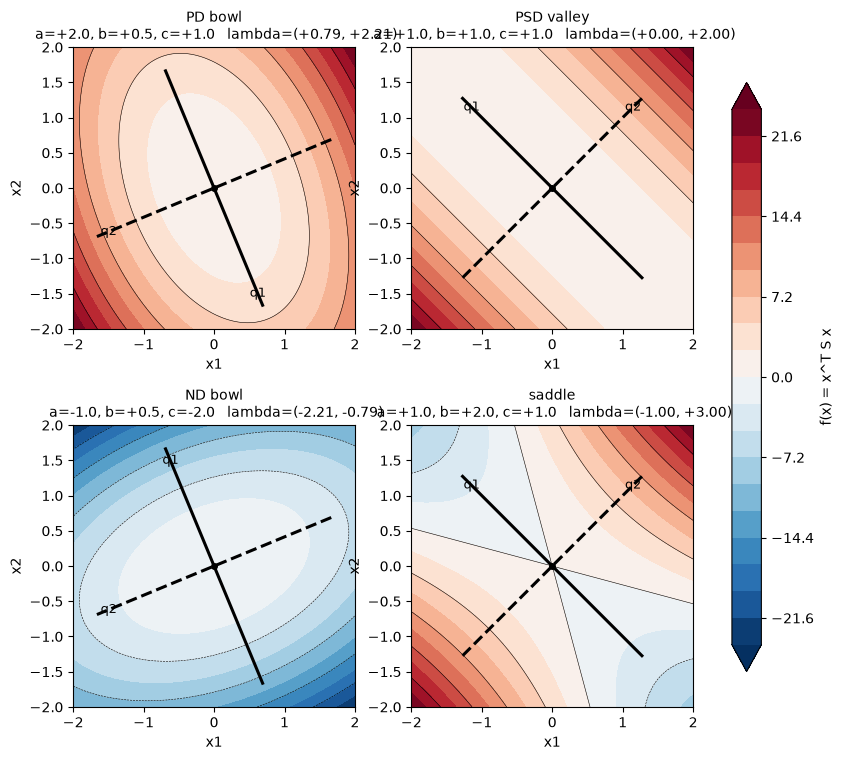

In [3]:
# --- Explore: the four canonical shapes ----------------------------------
presets = [
    ("PD bowl", 2.0, 0.5, 1.0),
    ("PSD valley", 1.0, 1.0, 1.0),
    ("ND bowl", -1.0, 0.5, -2.0),
    ("saddle", 1.0, 2.0, 1.0),
]

print("%-12s %5s %5s %5s | %9s %9s | %9s %9s | %s"
      % ("case", "a", "b", "c", "lambda1", "lambda2", "det", "trace", "type"))
for label, a, b, c in presets:
    d = eigen_summary(a, b, c, n=81)
    v = d["vals"]
    print("%-12s %+5.1f %+5.1f %+5.1f | %+9.4f %+9.4f | %+9.4f %+9.4f | %s"
          % (label, a, b, c, v[0], v[1], d["det"], d["trace"], d["kind"]))

print("\n--- checks for every preset ---")
for label, a, b, c in presets:
    d = eigen_summary(a, b, c, n=81)
    v, Q = d["vals"], d["vecs"]
    print("%-12s  S=Q diag Q^T: %-5s  det=lam1 lam2: %-5s  Q^T Q=I: %-5s  S q_i=lam_i q_i: %s"
          % (label,
             np.allclose(d["S"], Q @ np.diag(v) @ Q.T),
             np.allclose(d["det"], np.prod(v)),
             np.allclose(Q.T @ Q, np.eye(2)),
             np.allclose(d["S"] @ Q, Q * v)))

# level set f = 1 for the PD default: semi-axis lengths along q1 and q2
axis_lengths = 1.0 / np.sqrt(vals0)
print("\nPD default: level f = 1 has semi-axis lengths", np.round(axis_lengths, 4),
      "along q1 and q2")
print("q1 . q2 =", np.dot(Q0[:, 0], Q0[:, 1]),
      " (the two axes are perpendicular)")


# --- the four shapes as contour panels -----------------------------------
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (label, a, b, c) in zip(axes.ravel(), presets):
    d = eigen_summary(a, b, c, n=121)
    vmax = max(np.abs(d["Z"]).max(), 1e-9)
    levels = np.linspace(-vmax, vmax, 21)
    cf = ax.contourf(d["X"], d["Y"], d["Z"], levels=levels,
                     cmap="RdBu_r", extend="both")
    ax.contour(d["X"], d["Y"], d["Z"], levels=levels[::2],
               colors="black", linewidths=0.4)
    for i in range(2):
        q = d["vecs"][:, i]
        L = 1.8
        ax.plot([-L * q[0], L * q[0]], [-L * q[1], L * q[1]],
                color="black", lw=2.2,
                ls="solid" if i == 0 else "dashed")
        ax.annotate("q%d" % (i + 1), xy=(0.90 * L * q[0], 0.90 * L * q[1]),
                    fontsize=9, ha="center", va="center")
    ax.plot([0], [0], "o", color="black", ms=4)
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title("%s\n a=%+.1f, b=%+.1f, c=%+.1f   lambda=(%+.2f, %+.2f)"
                 % (label, a, b, c, d["vals"][0], d["vals"][1]), fontsize=10)
fig.colorbar(cf, ax=axes.ravel().tolist(), shrink=0.85, label="f(x) = x^T S x")
plt.show()


### Explain

**How do the signs of the eigenvalues determine the shape?**

Because S is symmetric, it has a real orthonormal eigenbasis: S = QΛQᵀ with
Λ = diag(λ1, λ2) and QᵀQ = I. In the rotated coordinates y = Qᵀx,

    f(x) = xᵀSx = yᵀΛy = λ1 y1² + λ2 y2².

The two signs therefore decide everything:

- **λ1 > 0 and λ2 > 0:** both terms are positive for x ≠ 0, so f has a single minimum
  at the origin. The graph is an upward bowl and the level sets f = c > 0 are ellipses.
  This is the positive definite case.
- **λ1 < 0 and λ2 < 0:** both terms are negative, so the graph is an upside-down bowl
  with a maximum at the origin. This is negative definite.
- **One eigenvalue zero, the other positive:** say λ1 = 0 and λ2 > 0. Then
  f = λ2 y2² does not depend on y1 at all. The graph is a parabolic cylinder: a valley
  whose floor is the whole line along q1. The matrix is positive semidefinite, not
  positive definite. If the nonzero eigenvalue is negative, the same picture is a ridge
  instead of a valley.
- **λ1 < 0 < λ2:** f increases along q2 and decreases along q1, so the origin is a
  saddle. Level sets are hyperbolas (the level f = 0 is a pair of lines through the
  origin). This is the indefinite case.

The 2×2 determinant and trace summarise the same information:
det(S) = λ1λ2 and trace(S) = λ1 + λ2. Thus det < 0 means indefinite; det > 0 with
trace > 0 means positive definite; det > 0 with trace < 0 means negative definite;
det = 0 with a nonzero trace means semidefinite (one zero eigenvalue). The Explore
table shows these combinations numerically: (0.793, 2.207) for the PD bowl,
(0, 2) for the PSD valley, (−2.207, −0.793) for the ND bowl, and (−1, 3) for the
saddle.

**Why do the contour ellipses align with the eigenvectors?**

In the eigenbasis the quadratic form has no cross term: f = λ1 y1² + λ2 y2². A level
set f = c is therefore

    (y1 / sqrt(c/λ1))² + (y2 / sqrt(c/λ2))² = 1

for c and both eigenvalues positive. This is an ellipse whose axes are the coordinate
axes y1 and y2, with semi-axis lengths sqrt(c/λ1) and sqrt(c/λ2). The map y = Qᵀx is a
rotation (or reflection), so when we go back to the x-plane those coordinate axes become
the eigenvector directions q1 and q2. The ellipse is only rotated, not deformed, so its
axes still point along q1 and q2. For the default matrix the eigenvalues are 0.7929 and
2.2071, so the level f = 1 has semi-axis lengths 1.123 and 0.673 along q1 = (−0.924,
0.383) and q2 = (0.383, 0.924); the printed dot product q1·q2 is zero.

The gradient gives the same statement locally: ∇f(x) = 2Sx, and on the eigenvector q_i
this is 2λ_i q_i, parallel to q_i. A level curve is perpendicular to its gradient, so at
the point where the curve crosses q_i it is perpendicular to q_i: q_i is a principal
axis of the ellipse. For an indefinite S the same diagonal form shows that the axes of
the hyperbolic level sets are still q1 and q2, although the asymptotes are generally
other lines. When λ1 = λ2 the level sets are circles and every orthonormal pair
of directions is an eigenbasis, so the axes are no longer unique. When one eigenvalue is
zero, the corresponding semi-axis is infinite and the "ellipse" degenerates into a pair
of parallel lines; that is exactly the flat valley seen in the PSD panel.

## 2.2 — A sphere becomes an ellipsoid

### Task

Take an orthonormal basis Q and Λ = diag(λ1, λ2), and let S = QΛQᵀ be the symmetric
positive definite matrix. Apply S to every point v of the unit circle **step by step**:
first Qᵀ, then Λ, then Q. Plot the three stages, with the original circle as a reference.

    v    ->    Qᵀ v    ->    Λ Qᵀ v    ->    Q Λ Qᵀ v = S v

The first step Qᵀ rotates the circle: a rotation maps the unit circle onto itself, so the
curve looks unchanged and only the marked points move. The second step stretches the
coordinate axes by λ1 and λ2 and turns the circle into an axis-aligned ellipse with those
semi-axes. The third step rotates that ellipse back, so its axes end up along the columns
of Q. The final curve is exactly the image of the unit circle under S.

The default here is θ = 30°, λ1 = 2, λ2 = 0.6, so the final ellipse has semi-axis lengths
2 and 0.6.

theta = 30.0 deg,  Q (columns are the eigen-directions) =
[[ 0.866 -0.5  ]
 [ 0.5    0.866]]

Lambda = diag(2.000, 0.600)

S = Q Lambda Q^T =
[[1.65   0.6062]
 [0.6062 0.95  ]]

eigenvalues of S (ascending): [0.6 2. ]
eigenvectors of S (columns of Q):
[[ 0.5   -0.866]
 [-0.866 -0.5  ]]

classification: positive definite: bowl

--- checks ---
Q is orthogonal                    : True
S is symmetric                     : True
S = Q diag(lam1, lam2) Q^T         : True
Q^T v keeps the unit circle        : True
Lambda Q^T v is an axis-aligned    : True
Q Lambda Q^T v equals S v          : True

final ellipse: semi-axis along q1 = 2.0000  (lambda1 = 2.0000)
final ellipse: semi-axis along q2 = 0.6000  (lambda2 = 0.6000)
semi-axis lengths equal the eigenvalues: True

the four marked points, phi = 0, 90, 180, 270 deg:
  point 1: v=(+1.00, +0.00) -> Q^T v=(+0.87, -0.50) -> S v=(+1.65, +0.61)
  point 2: v=(+0.00, +1.00) -> Q^T v=(+0.50, +0.87) -> S v=(+0.61, +0.95)
  point 3: v=(-1.00, +0.00) -> 

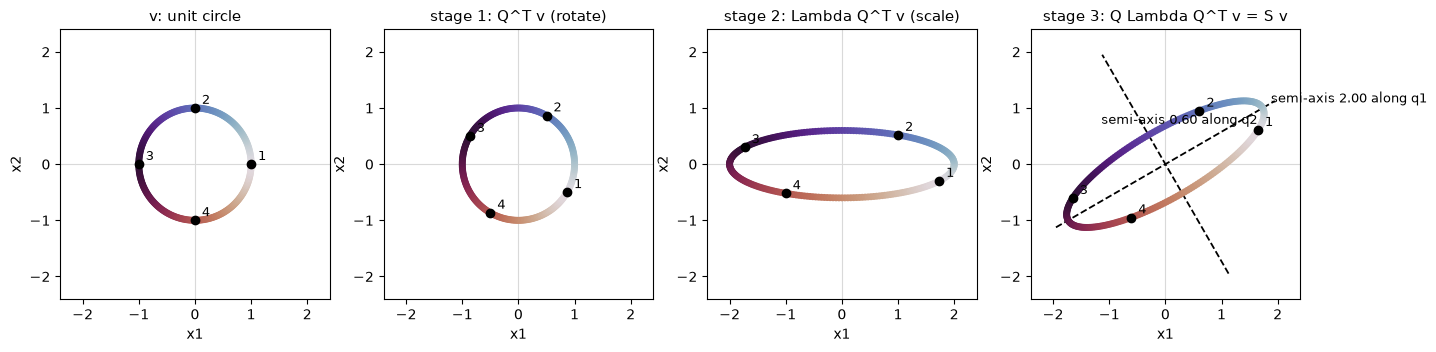

In [4]:
# --- Task: unit circle -> ellipse in the three steps Q^T, Lambda, Q --------
theta0, lam1_0, lam2_0 = 30.0, 2.0, 0.6
d = ellipse_stages(theta0, lam1_0, lam2_0)
Q, L, S = d["Q"], d["L"], d["S"]

vals, vecs = np.linalg.eigh(S)
print("theta = %.1f deg,  Q (columns are the eigen-directions) =" % theta0)
print(Q)
print("\nLambda = diag(%.3f, %.3f)" % (lam1_0, lam2_0))
print("\nS = Q Lambda Q^T =")
print(S)
print("\neigenvalues of S (ascending):", vals)
print("eigenvectors of S (columns of Q):")
print(vecs)
print("\nclassification:", shape_type(vals))

print("\n--- checks ---")
print("Q is orthogonal                    :", np.allclose(Q.T @ Q, np.eye(2)))
print("S is symmetric                     :", np.allclose(S, S.T))
print("S = Q diag(lam1, lam2) Q^T         :", np.allclose(S, Q @ L @ Q.T))
print("Q^T v keeps the unit circle        :", np.allclose(np.sum(d["V1"] ** 2, axis=0), 1.0))
print("Lambda Q^T v is an axis-aligned    :",
      np.allclose((d["V2"][0] / lam1_0) ** 2 + (d["V2"][1] / lam2_0) ** 2, 1.0, atol=1e-9))
print("Q Lambda Q^T v equals S v          :", np.allclose(d["V3"], S @ d["V"]))

q1, q2 = Q[:, 0], Q[:, 1]
semi1 = np.abs(d["V3"].T @ q1).max()
semi2 = np.abs(d["V3"].T @ q2).max()
print("\nfinal ellipse: semi-axis along q1 = %.4f  (lambda1 = %.4f)" % (semi1, lam1_0))
print("final ellipse: semi-axis along q2 = %.4f  (lambda2 = %.4f)" % (semi2, lam2_0))
print("semi-axis lengths equal the eigenvalues:",
      np.allclose([semi1, semi2], [lam1_0, lam2_0]))

print("\nthe four marked points, phi = 0, 90, 180, 270 deg:")
phases4 = np.arange(4) * np.pi / 2
for j, phi in enumerate(phases4):
    kk = np.searchsorted(d["t"], phi)
    v, s1v, s3v = d["V"][:, kk], d["V1"][:, kk], d["V3"][:, kk]
    print("  point %d: v=(%+.2f, %+.2f) -> Q^T v=(%+.2f, %+.2f) -> S v=(%+.2f, %+.2f)"
          % (j + 1, v[0], v[1], s1v[0], s1v[1], s3v[0], s3v[1]))


# --- the four stages as four panels --------------------------------------
stages = [d["V"], d["V1"], d["V2"], d["V3"]]
titles = ["v: unit circle", "stage 1: Q^T v (rotate)",
          "stage 2: Lambda Q^T v (scale)", "stage 3: Q Lambda Q^T v = S v"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, P, title in zip(axes, stages, titles):
    ax.plot(np.append(P[0], P[0][0]), np.append(P[1], P[1][0]), color="0.4", lw=1.2)
    ax.scatter(P[0], P[1], c=d["t"], cmap="twilight", s=16, zorder=3)
    kk = np.searchsorted(d["t"], phases4)
    ax.plot(P[0, kk], P[1, kk], "o", color="black", ms=6, zorder=4)
    for j, idx in enumerate(kk):
        ax.annotate(str(j + 1), xy=(P[0, idx], P[1, idx]), xytext=(5, 3),
                    textcoords="offset points", fontsize=9)
    ax.axhline(0, color="0.85", lw=0.8)
    ax.axvline(0, color="0.85", lw=0.8)
    ax.set_xlim(-2.4, 2.4)
    ax.set_ylim(-2.4, 2.4)
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(title, fontsize=11)
Lq = 2.25
for i in range(2):
    q = Q[:, i]
    axes[3].plot([-Lq * q[0], Lq * q[0]], [-Lq * q[1], Lq * q[1]],
                 color="black", ls="--", lw=1.3, zorder=2)
axes[3].annotate("semi-axis %.2f along q1" % lam1_0,
                 xy=(lam1_0 * q1[0], lam1_0 * q1[1]), xytext=(6, 4),
                 textcoords="offset points", fontsize=9)
axes[3].annotate("semi-axis %.2f along q2" % lam2_0,
                 xy=(lam2_0 * q2[0], lam2_0 * q2[1]), xytext=(-34, 8),
                 textcoords="offset points", fontsize=9)
plt.show()

In [5]:
# --- interactive: theta, lambda1 and lambda2 sliders and preset buttons ---
N_CIRCLE = 121
PHASES = np.arange(4) * np.pi / 2
MARK_TEXT = ["1", "2", "3", "4"]


def stage_traces(d, minimal=False):
    """Eight traces: a coloured ring plus four marked points, for the four stages.

    With minimal=True only x and y are set, so a frame moves the points and
    inherits the marker styling from the matching base trace.
    """
    traces = []
    kk = np.searchsorted(d["t"], PHASES)
    for P in (d["V"], d["V1"], d["V2"], d["V3"]):
        P = np.round(P, 4)
        Pm = P[:, kk]
        if minimal:
            traces.append(go.Scatter(x=P[0], y=P[1]))
            traces.append(go.Scatter(x=Pm[0], y=Pm[1]))
        else:
            traces.append(go.Scatter(x=P[0], y=P[1], mode="markers",
                                     marker=dict(size=5, color=d["t"], colorscale=TWILIGHT,
                                                 showscale=False,
                                                 line=dict(width=0.4, color="white"))))
            traces.append(go.Scatter(x=Pm[0], y=Pm[1], mode="markers+text",
                                     marker=dict(size=9, color="black"),
                                     text=MARK_TEXT, textposition="top center",
                                     textfont=dict(size=10, color="black")))
    return traces


def stage_title(theta, lam1, lam2):
    lo = min(lam1, lam2)
    kind = ("positive definite" if lo > 0 else
            ("positive semidefinite (singular)" if lo == 0 else "not positive definite"))
    return ("theta = %.1f deg   |   lambda1 = %.2f, lambda2 = %.2f   |   det(S) = %.3f<br>"
            "semi-axes %.2f along q1 and %.2f along q2   |   %s"
            % (theta, lam1, lam2, lam1 * lam2, lam1, lam2, kind))


def make_stage_frame(name, theta, lam1, lam2):
    d = ellipse_stages(theta, lam1, lam2, n=N_CIRCLE)
    return go.Frame(name=name, data=stage_traces(d, minimal=True), traces=list(range(8)),
                    layout=go.Layout(title_text=stage_title(theta, lam1, lam2)))


base = ellipse_stages(theta0, lam1_0, lam2_0, n=N_CIRCLE)
fig = make_subplots(
    rows=1, cols=4,
    subplot_titles=("v: unit circle", "stage 1: Q^T v", "stage 2: Lambda Q^T v",
                    "stage 3: S v = Q Lambda Q^T v"),
)
trs = stage_traces(base)
for col in range(4):
    fig.add_trace(trs[2 * col], row=1, col=col + 1)
    fig.add_trace(trs[2 * col + 1], row=1, col=col + 1)

theta_vals = np.round(np.arange(-90.0, 90.001, 15.0), 10)
lam1_vals = np.round(np.arange(0.25, 3.0001, 0.25), 10)
lam2_vals = np.round(np.arange(0.0, 1.5001, 0.1), 10)

theta_names = ["theta=%.1f" % v for v in theta_vals]
lam1_names = ["lam1=%.3f" % v for v in lam1_vals]
lam2_names = ["lam2=%.3f" % v for v in lam2_vals]

frames = ([make_stage_frame(nm, v, lam1_0, lam2_0) for nm, v in zip(theta_names, theta_vals)]
          + [make_stage_frame(nm, theta0, v, lam2_0) for nm, v in zip(lam1_names, lam1_vals)]
          + [make_stage_frame(nm, theta0, lam1_0, v) for nm, v in zip(lam2_names, lam2_vals)])

presets = [
    ("preset:default", "default", 30.0, 2.0, 0.6),
    ("preset:axis", "theta = 0", 0.0, 2.0, 0.6),
    ("preset:circle", "circle (lam1 = lam2)", 30.0, 1.0, 1.0),
    ("preset:almost", "almost flat", 30.0, 2.0, 0.05),
    ("preset:flat", "exactly flat", 30.0, 2.0, 0.0),
]
frames += [make_stage_frame(name, t, l1, l2) for name, label, t, l1, l2 in presets]
fig.frames = frames


def animate_step(name):
    return dict(method="animate", label=name.split("=")[-1],
                args=[[name], dict(mode="immediate",
                                   frame=dict(duration=0, redraw=True),
                                   transition=dict(duration=0))])


def slider_for(prefix, frame_names, base_value, values):
    steps = [animate_step(nm) for nm in frame_names]
    active = int(np.argmin(np.abs(np.asarray(values) - base_value)))
    return dict(active=active, currentvalue=dict(prefix=prefix + " = ",
                                                font=dict(size=12)),
                steps=steps, pad=dict(t=25))


buttons = [dict(label=label, method="animate",
                args=[[name], dict(mode="immediate",
                                   frame=dict(duration=0, redraw=True),
                                   transition=dict(duration=0))])
           for name, label, t, l1, l2 in presets]

fig.update_layout(
    height=440, width=1320, showlegend=False,
    title_text=stage_title(theta0, lam1_0, lam2_0),
    updatemenus=[dict(type="buttons", direction="right", x=0.0, y=1.12,
                      xanchor="left", yanchor="bottom", showactive=True,
                      buttons=buttons)],
    sliders=[dict(slider_for("theta", theta_names, theta0, theta_vals),
                  x=0.02, len=0.30, y=-0.20),
             dict(slider_for("lambda1", lam1_names, lam1_0, lam1_vals),
                  x=0.36, len=0.30, y=-0.20),
             dict(slider_for("lambda2", lam2_names, lam2_0, lam2_vals),
                  x=0.70, len=0.30, y=-0.20)],
    margin=dict(l=20, r=20, t=155, b=115),
)
for col, xa in enumerate(["x", "x2", "x3", "x4"]):
    fig.update_xaxes(range=[-3.3, 3.3], row=1, col=col + 1)
    fig.update_yaxes(range=[-3.3, 3.3], scaleanchor=xa, scaleratio=1, row=1, col=col + 1)
print("figure payload: %d frames, %.0f kB of JSON" % (len(fig.frames), len(fig.to_json()) / 1024))
fig.show()

figure payload: 46 frames, 681 kB of JSON


### Explore

Drive λ2 towards zero and watch the ellipse flatten.

- **Almost flat:** λ2 = 0.05. The ellipse is extremely thin, its minor semi-axis is 0.05,
  and det(S) = λ1·λ2 = 0.1 is small but nonzero. S is still positive definite and
  invertible.
- **Exactly flat:** λ2 = 0. The minor semi-axis collapses to zero, so the ellipse
  degenerates into the segment from −λ1 q1 to +λ1 q1. Now det(S) = 0, S is only positive
  semidefinite, and its null space is the line spanned by q2: the whole circle is mapped
  onto that segment, and two points that differ only in their q2-component land on the
  same image point.

The table and the three panels below record the numbers for these choices.

case            lam1   lam2 |       det |   semi-1   semi-2 |      area | type
default PD      2.00   0.60 |   +1.2000 |   2.0000   0.6000 |    3.7699 | positive definite: bowl
almost flat     2.00   0.05 |   +0.1000 |   2.0000   0.0500 |    0.3142 | positive definite: bowl
exactly flat    2.00   0.00 |   +0.0000 |   2.0000   0.0000 |    0.0000 | positive semidefinite: valley with a flat line

--- checks ---
default PD     S = Q diag Q^T: True   det = lam1 lam2: True   Q^T v keeps circle: True   S v = Q Lambda Q^T v: True
almost flat    S = Q diag Q^T: True   det = lam1 lam2: True   Q^T v keeps circle: True   S v = Q Lambda Q^T v: True
exactly flat   S = Q diag Q^T: True   det = lam1 lam2: True   Q^T v keeps circle: True   S v = Q Lambda Q^T v: True

exactly flat (lambda2 = 0):
  det(S)                        = 8.326672684688688e-17
  eigenvalues of S              = [0. 2.]
  S is positive semidefinite    : True
  all S v lie on the q1-axis    : True
  extreme point along q1        : 1

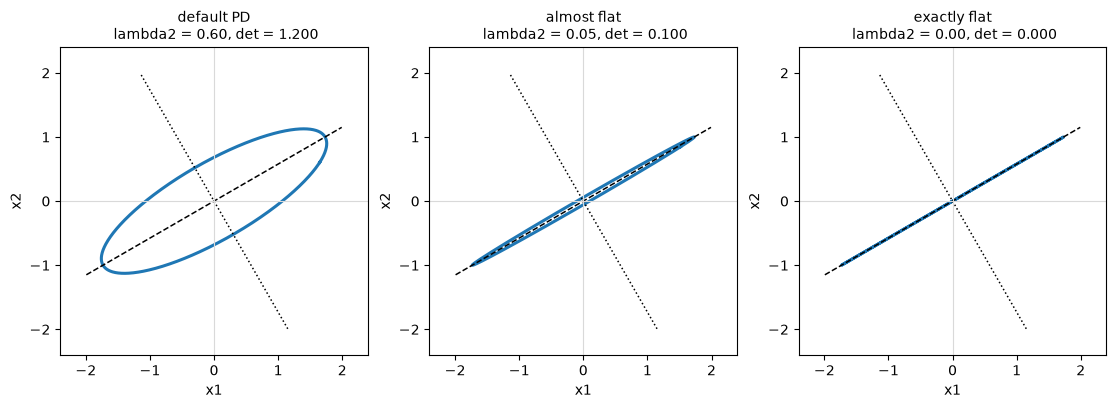

In [6]:
# --- Explore: one eigenvalue almost zero, then exactly zero ---------------
cases = [
    ("default PD", 30.0, 2.0, 0.6),
    ("almost flat", 30.0, 2.0, 0.05),
    ("exactly flat", 30.0, 2.0, 0.0),
]

print("%-13s %6s %6s | %9s | %8s %8s | %9s | %s"
      % ("case", "lam1", "lam2", "det", "semi-1", "semi-2", "area", "type"))
for label, th, l1, l2 in cases:
    d = ellipse_stages(th, l1, l2, n=2001)
    s1 = np.abs(d["V3"].T @ d["Q"][:, 0]).max()
    s2 = np.abs(d["V3"].T @ d["Q"][:, 1]).max()
    print("%-13s %6.2f %6.2f | %+9.4f | %8.4f %8.4f | %9.4f | %s"
          % (label, l1, l2, l1 * l2, s1, s2, np.pi * l1 * l2,
             shape_type(np.linalg.eigvalsh(d["S"]))))

print("\n--- checks ---")
for label, th, l1, l2 in cases:
    d = ellipse_stages(th, l1, l2, n=2001)
    S = d["S"]
    print("%-13s  S = Q diag Q^T: %-5s  det = lam1 lam2: %-5s  "
          "Q^T v keeps circle: %-5s  S v = Q Lambda Q^T v: %s"
          % (label,
             np.allclose(S, d["Q"] @ d["L"] @ d["Q"].T),
             np.allclose(np.linalg.det(S), l1 * l2),
             np.allclose(np.sum(d["V1"] ** 2, axis=0), 1.0),
             np.allclose(d["V3"], S @ d["V"])))

df = ellipse_stages(30.0, 2.0, 0.0, n=2001)
qf1, qf2 = df["Q"][:, 0], df["Q"][:, 1]
phi = 0.7
v_a = np.cos(phi) * qf1 + np.sin(phi) * qf2
v_b = np.cos(phi) * qf1 - np.sin(phi) * qf2
print("\nexactly flat (lambda2 = 0):")
print("  det(S)                        =", np.linalg.det(df["S"]))
print("  eigenvalues of S              =", np.linalg.eigvalsh(df["S"]))
print("  S is positive semidefinite    :", np.all(np.linalg.eigvalsh(df["S"]) >= -1e-12))
print("  all S v lie on the q1-axis    :", np.allclose(df["V3"].T @ qf2, 0.0, atol=1e-12))
print("  extreme point along q1        :", np.abs(df["V3"].T @ qf1).max())
print("  equals lam1                   :", np.allclose(np.abs(df["V3"].T @ qf1).max(), 2.0))
print("  two distinct unit vectors with the same image:",
      np.allclose(df["S"] @ v_a, df["S"] @ v_b), " and v_a != v_b :",
      not np.allclose(v_a, v_b))


# --- the flattened ellipses ----------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
for ax, (label, th, l1, l2) in zip(axes, cases):
    d = ellipse_stages(th, l1, l2, n=721)
    P = d["V3"]
    ax.plot(np.append(P[0], P[0][0]), np.append(P[1], P[1][0]), color="C0", lw=2.2)
    q1, q2 = d["Q"][:, 0], d["Q"][:, 1]
    ax.plot([-2.3 * q1[0], 2.3 * q1[0]], [-2.3 * q1[1], 2.3 * q1[1]],
            color="black", ls="--", lw=1.1)
    ax.plot([-2.3 * q2[0], 2.3 * q2[0]], [-2.3 * q2[1], 2.3 * q2[1]],
            color="black", ls=":", lw=1.1)
    ax.axhline(0, color="0.85", lw=0.8)
    ax.axvline(0, color="0.85", lw=0.8)
    ax.set_xlim(-2.4, 2.4)
    ax.set_ylim(-2.4, 2.4)
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title("%s\n lambda2 = %.2f, det = %.3f" % (label, l2, l1 * l2), fontsize=10)
plt.show()

### Explain

**What are the semi-axis lengths and directions of the final ellipse?**

Write v in the eigenbasis, v = (v·q1) q1 + (v·q2) q2, with v·q1 = cos φ and v·q2 = sin φ
on the unit circle. Since S q1 = λ1 q1 and S q2 = λ2 q2,

    S v = λ1 (v·q1) q1 + λ2 (v·q2) q2 = λ1 cos φ q1 + λ2 sin φ q2.

So the coordinates of the image in the eigenbasis are (w·q1, w·q2) = (λ1 cos φ, λ2 sin φ),
and these satisfy

    (w·q1 / λ1)² + (w·q2 / λ2)² = 1.

That is an ellipse centred at the origin whose semi-axis **lengths** are λ1 and λ2 and
whose semi-axis **directions** are the eigenvectors q1 and q2; the major axis points along
the eigenvector of the larger eigenvalue. For the default (θ = 30°, λ1 = 2, λ2 = 0.6) the
semi-axes are 2 and 0.6 along q1 = (cos 30°, sin 30°) = (0.866, 0.500) and
q2 = (−0.500, 0.866), and the printed dot product q1·q2 is zero, so the axes are
perpendicular. The three steps explain the result: Qᵀ rotates the circle onto itself, so
the curve is unchanged; Λ stretches the two coordinate directions by λ1 and λ2, turning
the circle into the axis-aligned ellipse with semi-axes λ1 and λ2; Q then rotates that
ellipse so its axes become the columns of Q.

Equivalently, the image of the unit circle is the solution set of |S⁻¹ w| = 1, that is
wᵀ S⁻² w = 1. With S⁻² = Q Λ⁻² Qᵀ this is again
(w·q1 / λ1)² + (w·q2 / λ2)² = 1, the same ellipse. This is the dual statement of the
level sets of 2.1: there the level sets of xᵀ S x have semi-axes sqrt(c/λ_i), whereas the
image of the unit circle under S has semi-axes λ_i.

**What happens as one eigenvalue goes to zero?**

Put λ2 → 0. The minor semi-axis λ2 shrinks to zero, so the ellipse flattens onto the
segment from −λ1 q1 to +λ1 q1. The determinant det(S) = λ1 λ2 tends to 0, the area
π λ1 λ2 tends to 0, and the condition number λ1 / λ2 tends to infinity. At λ2 = 0
exactly, S is singular and only positive semidefinite: its null space is the line spanned
by q2, and the stretch along q2 is destroyed. The map is now many-to-one — the two unit
vectors v = cos φ q1 + sin φ q2 and v′ = cos φ q1 − sin φ q2 differ only in their
q2-component, so both are sent to the single point λ1 cos φ q1 on the q1-axis. The image
of the whole circle is the segment between ±λ1 q1, a set of measure zero in the plane. In
three dimensions the same construction sends the unit sphere to an ellipsoid with
semi-axis lengths λ1, λ2, λ3.

## 2.3 — Aᵀ A is always PSD

### Task

Generate 1,000 random matrices A — some square, some tall, some rank-deficient — record
the smallest eigenvalue of AᵀA for each, and plot a histogram of the 1,000 values.

The matrices come in four equal families: square full-rank, tall full-rank, square
rank-deficient and tall rank-deficient. A rank-deficient matrix is built as a product
A = B C whose inner dimension k is smaller than its number of columns n, so its rank is
at most k < n and AᵀA is singular by construction. Tall means more rows than columns.

The left panel is the linear histogram; the right panel repeats it on logarithmic axes so
the values within round-off of zero are separated from the positive tail. The printed
table, the checks and the numbers after the figure record the values behind both panels.

family                   count  min lam_min       median  max lam_min   zero
square                     250    1.704e-06    9.970e-02    1.684e+00      0
tall                       250    2.497e-03    1.220e+00    9.096e+00      0
square, rank-deficient     250   -2.724e-14   -6.523e-16    1.209e-14    250
tall, rank-deficient       250   -3.910e-14   -9.194e-16    2.837e-14    250

overall: 1000 matrices, 500 full column rank, 500 rank-deficient
lambda_min over the full-rank matrices   : [1.704e-06, 9.096e+00]
lambda_min over the rank-deficient ones  : [-3.910e-14, 2.837e-14]
largest |lambda_min| among rank-deficient: 3.910e-14
smallest lambda_min among full-rank      : 1.704e-06
counted as zero: |lambda_min| <= 1e-10 max(1, lambda_max)  ->  500 of 1000

--- checks over all 1,000 matrices ---
A^T A is symmetric                       : True
all eigenvalues of A^T A are >= -tol     : True
eigenvalues of A^T A are sigma_i(A)^2    : True
rank(A^T A) = rank(A)                    : True
nul

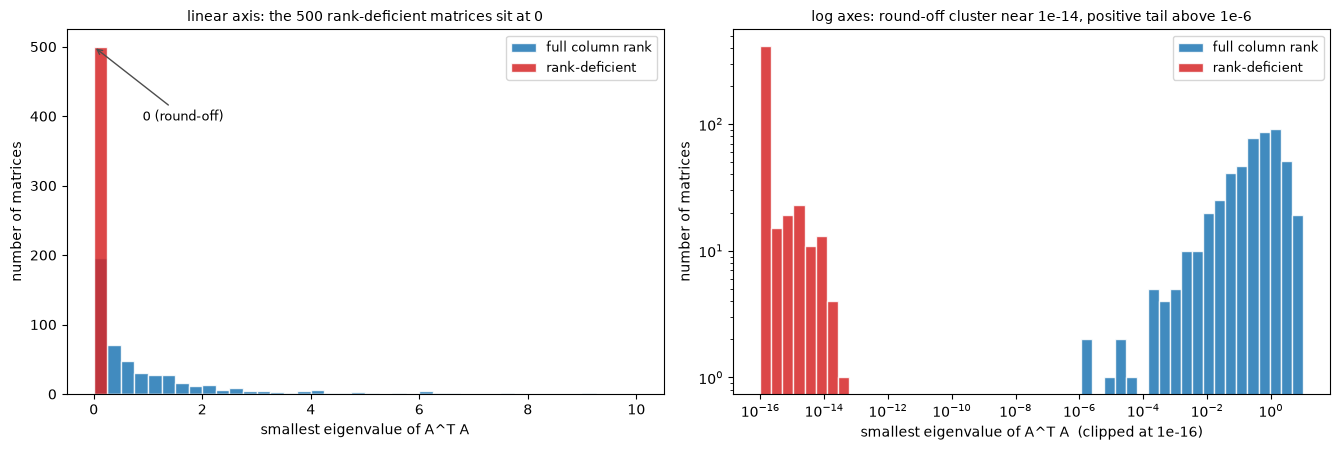

In [7]:
# --- Task: smallest eigenvalue of A^T A for 1,000 random matrices --------
RNG = np.random.default_rng(2027)
N_MATRICES = 1000
FAMILIES = ["square", "tall", "square, rank-deficient", "tall, rank-deficient"]


def random_matrix(rng, family):
    """Draw one A of the requested family; rank-deficient ones factor through k < n."""
    if family in ("square", "tall"):
        n = int(rng.integers(2, 7)) if family == "square" else int(rng.integers(2, 6))
        m = n if family == "square" else n + int(rng.integers(1, 6))
        return rng.standard_normal((m, n))
    n = int(rng.integers(3, 7))
    k = int(rng.integers(1, n))
    m = n if family == "square, rank-deficient" else n + int(rng.integers(1, 6))
    return rng.standard_normal((m, k)) @ rng.standard_normal((k, n))


records = []
for i in range(N_MATRICES):
    family = FAMILIES[i % len(FAMILIES)]
    A = random_matrix(RNG, family)
    gram = A.T @ A
    ev = np.linalg.eigvalsh(gram)
    records.append(dict(family=family, A=A, gram=gram, shape=A.shape,
                        rank=np.linalg.matrix_rank(A), ev=ev,
                        lam_min=ev[0], lam_max=ev[-1]))

lam_min = np.array([r["lam_min"] for r in records])
lam_max = np.array([r["lam_max"] for r in records])
rank = np.array([r["rank"] for r in records])
ncols = np.array([r["shape"][1] for r in records])
tol = 1e-10 * np.maximum(lam_max, 1.0)
is_zero = np.abs(lam_min) <= tol

print("%-24s %5s %12s %12s %12s %6s"
      % ("family", "count", "min lam_min", "median", "max lam_min", "zero"))
for family in FAMILIES:
    sel = np.array([r["family"] == family for r in records])
    print("%-24s %5d %12.3e %12.3e %12.3e %6d"
          % (family, sel.sum(), lam_min[sel].min(), np.median(lam_min[sel]),
             lam_min[sel].max(), is_zero[sel].sum()))

print("\noverall: %d matrices, %d full column rank, %d rank-deficient"
      % (N_MATRICES, (rank == ncols).sum(), (rank < ncols).sum()))
print("lambda_min over the full-rank matrices   : [%.3e, %.3e]"
      % (lam_min[rank == ncols].min(), lam_min[rank == ncols].max()))
print("lambda_min over the rank-deficient ones  : [%.3e, %.3e]"
      % (lam_min[rank < ncols].min(), lam_min[rank < ncols].max()))
print("largest |lambda_min| among rank-deficient: %.3e"
      % np.abs(lam_min[rank < ncols]).max())
print("smallest lambda_min among full-rank      : %.3e"
      % lam_min[rank == ncols].min())
print("counted as zero: |lambda_min| <= 1e-10 max(1, lambda_max)  ->  %d of %d"
      % (is_zero.sum(), N_MATRICES))

print("\n--- checks over all 1,000 matrices ---")
print("A^T A is symmetric                       :",
      all(np.allclose(r["gram"], r["gram"].T) for r in records))
print("all eigenvalues of A^T A are >= -tol     :",
      all(np.all(r["ev"] >= -1e-10 * max(1.0, r["lam_max"])) for r in records))
print("eigenvalues of A^T A are sigma_i(A)^2    :",
      all(np.allclose(np.sort(r["ev"]),
                      np.sort(np.linalg.svd(r["A"], compute_uv=False) ** 2))
          for r in records))
print("rank(A^T A) = rank(A)                    :",
      all(np.linalg.matrix_rank(r["gram"]) == r["rank"] for r in records))
print("nullity(A^T A) = n - rank(A)             :",
      all(np.sum(np.abs(r["ev"]) <= 1e-10 * max(1.0, r["lam_max"]))
          == r["shape"][1] - r["rank"] for r in records))
print("lambda_min is zero iff rank(A) < n       :",
      np.array_equal(is_zero, rank < ncols))

rayleigh_ok = True
for r in records:
    X = RNG.standard_normal((r["shape"][1], 8))
    X /= np.linalg.norm(X, axis=0)
    lhs = np.einsum("ik,ij,jk->k", X, r["gram"], X)
    rayleigh_ok &= np.allclose(lhs, np.sum((r["A"] @ X) ** 2, axis=0))
print("x^T A^T A x = ||A x||^2 on random unit x :", rayleigh_ok)

# one rank-deficient and one full-rank matrix, with their extreme eigenvectors
i_def = int(np.flatnonzero(rank < ncols)[0])
i_full = int(np.flatnonzero(rank == ncols)[0])
for label, i in (("rank-deficient", i_def), ("full-rank", i_full)):
    r = records[i]
    vals, vecs = np.linalg.eigh(r["gram"])
    x = vecs[:, 0]
    print("\n%s example: A is %dx%d, rank %d, n = %d"
          % (label, r["shape"][0], r["shape"][1], r["rank"], r["shape"][1]))
    print("  lambda_min = %.3e,  lambda_max = %.3e,  det(A^T A) = %.3e"
          % (vals[0], vals[-1], np.linalg.det(r["gram"])))
    print("  smallest eigenvector x = (%s)"
          % ", ".join("%+.4f" % v for v in x))
    print("  ||A x|| = %.3e,  ||A^T A x|| = %.3e,  x^T A^T A x = %.3e"
          % (np.linalg.norm(r["A"] @ x), np.linalg.norm(r["gram"] @ x),
             x @ r["gram"] @ x))
    print("  x^T A^T A x equals ||A x||^2 and lambda_min:",
          np.allclose(x @ r["gram"] @ x, np.linalg.norm(r["A"] @ x) ** 2),
          np.allclose(x @ r["gram"] @ x, vals[0]))


# --- histogram: the linear view the sheet asks for, plus a log view ------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

bins_lin = np.linspace(0.0, np.ceil(lam_min.max()), 41)
axes[0].hist(lam_min[rank == ncols], bins=bins_lin, color="C0", alpha=0.85,
             edgecolor="white", label="full column rank")
axes[0].hist(np.clip(lam_min[rank < ncols], 0.0, None), bins=bins_lin,
             color="C3", alpha=0.85, edgecolor="white", label="rank-deficient")
axes[0].set_xlabel("smallest eigenvalue of A^T A")
axes[0].set_ylabel("number of matrices")
axes[0].set_title("linear axis: the %d rank-deficient matrices sit at 0"
                  % (rank < ncols).sum(), fontsize=10)
axes[0].legend(fontsize=9)
axes[0].annotate("0 (round-off)", xy=(0.0, is_zero.sum()),
                 xytext=(0.9, 0.75 * axes[0].get_ylim()[1]),
                 arrowprops=dict(arrowstyle="->", color="0.3"), fontsize=9)

bins_log = np.logspace(-16, np.log10(np.ceil(lam_min.max())), 50)
axes[1].hist(np.clip(lam_min[rank == ncols], 1e-16, None), bins=bins_log,
             color="C0", alpha=0.85, edgecolor="white", label="full column rank")
axes[1].hist(np.clip(lam_min[rank < ncols], 1e-16, None), bins=bins_log,
             color="C3", alpha=0.85, edgecolor="white", label="rank-deficient")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("smallest eigenvalue of A^T A  (clipped at 1e-16)")
axes[1].set_ylabel("number of matrices")
axes[1].set_title("log axes: round-off cluster near 1e-14, positive tail above 1e-6",
                  fontsize=10)
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

print("\n--- numbers behind the histogram ---")
print("  lambda_min <= 1e-10          : %d" % np.sum(lam_min <= 1e-10))
print("  1e-10 < lambda_min <= 1e-6   : %d" % np.sum((lam_min > 1e-10) & (lam_min <= 1e-6)))
print("  lambda_min > 1e-6            : %d" % np.sum(lam_min > 1e-6))
print("  linear bin [0, %.3f)         : %d (%d counted zero, %d small positive)"
      % (bins_lin[1], np.sum(lam_min < bins_lin[1]), is_zero.sum(),
         np.sum((lam_min > 0) & (lam_min < bins_lin[1]))))
print("  empty gap                    : (%.3e, %.3e)"
      % (np.abs(lam_min[rank < ncols]).max(), lam_min[rank == ncols].min()))
print("  log-panel range              : bins from %.0e to %.0e, %d bins"
      % (bins_log[0], bins_log[-1], len(bins_log) - 1))

### Explain

**Why AᵀA is always positive semidefinite.**

AᵀA is symmetric, (AᵀA)ᵀ = AᵀA, and for every x

    xᵀ AᵀA x = (Ax)ᵀ(Ax) = ‖Ax‖₂² ≥ 0,

because a sum of squares is never negative. That is the proof in [2.7]: the quadratic
form of AᵀA is the squared length of Ax, so it cannot be negative. Consequently AᵀA has
real, nonnegative eigenvalues. The run checks this for all 1,000 matrices, and also
checks xᵀAᵀAx = ‖Ax‖² on random unit vectors.

**When is the minimum exactly zero?**

The smallest eigenvalue is the minimum of the Rayleigh quotient over unit vectors,

    λ_min(AᵀA) = min over ‖x‖ = 1 of xᵀAᵀA x = min over ‖x‖ = 1 of ‖Ax‖₂²,

so it is exactly zero if and only if some nonzero x has Ax = 0 — that is, if and only if
the null space of A contains more than the zero vector. For an m×n matrix this means
rank(A) < n: A has at least one zero singular value, its columns are linearly dependent,
and AᵀA is singular.

The same equivalence gives the link with the null space of AᵀA:

    Ax = 0  ⇒  AᵀAx = 0,
    xᵀAᵀAx = ‖Ax‖₂² = 0  ⇒  Ax = 0,

so null(AᵀA) = null(A). Hence rank(AᵀA) = rank(A) = n − dim null(A), and AᵀA is singular
exactly when A does not have full column rank. When A does have full column rank — a
square invertible matrix, or a tall matrix whose n columns are independent — AᵀA is
positive definite and λ_min > 0. The run verifies rank(AᵀA) = rank(A) and
nullity(AᵀA) = n − rank(A) for all 1,000 matrices.

**What the 1,000 numbers show.**

The histogram has two clearly separated groups:

- 500 rank-deficient matrices (built with rank at most k < n): λ_min between −3.9×10⁻¹⁴
  and 2.8×10⁻¹⁴, i.e. zero within round-off. The negative values are round-off in
  eigvalsh, not a violation: the computed eigenvalues of a PSD matrix can come out
  slightly below zero, and every one of them is above −tol.
- 500 full-column-rank matrices (square or tall): λ_min between 1.7×10⁻⁶ and 9.1, all
  strictly positive.

The interval between 3.9×10⁻¹⁴ and 1.7×10⁻⁶ is empty. The threshold used to call a value
zero is |λ_min| ≤ 10⁻¹⁰ max(1, λ_max), which sits inside that gap. For the rank-deficient
example the smallest eigenvector x satisfies ‖Ax‖ ≈ 2.7×10⁻¹⁶ and xᵀAᵀAx ≈ 4.1×10⁻¹⁶;
for the full-rank example the same quantity is 0.132, the smallest singular value squared.

Since the eigenvalues of AᵀA are the squared singular values σᵢ(A)², λ_min = σ_min(A)²,
and σ_min = 0 exactly when the rank is deficient. This is the numerical signature of the
null space: a direction that A annihilates.